# 04. Two-Tower Retrieval: In-Batch Negatives, Softmax Cross-Entropy

**Objective.** Train a neural retriever with separate user and item towers in
PyTorch, using in-batch negatives and a softmax cross-entropy loss then index
item embeddings with FAISS and compare against Popularity and MF-BPR.

**Why two-tower on top of MF-BPR.** MF-BPR (notebook 03) only has an embedding
for users and items it saw during training. There's no way to score a user who
signs up tomorrow. The webapp's "Homepage (logged in)" flow needs to compute a
user embedding **at request time** from that user's history, which means the
user tower has to be a function of features, not a frozen per-user lookup table.
So here, the **user tower takes the user's interaction history as input** (mean-
pooled item embeddings + behavioral features) and produces an embedding via an
MLP. It is genuinely inductive, not a lookup.

**Why in-batch negatives + softmax instead of BPR's pairwise loss.** For each
`(user, positive item)` pair in a training batch, every *other* item in that
same batch doubles as a negative. No separate negative-sampling step needed.
The loss is then ordinary softmax cross-entropy over the batch×batch similarity
matrix (row i's positive is item i). This scales better than BPR-style
one-negative-per-step sampling and is the standard training objective for
large-scale two-tower retrieval (e.g. YouTube DNN, Facebook's DSSM-style
retrievers). Known caveat, documented where it matters below: a batch-mate's
item can by chance be something the user actually likes too (a false negative). It is an accepted approximation at this scale, correctable with popularity-based
sampling bias correction (listed as a bonus in the project spec, not implemented here).

**Depends on**: notebook 01's split (`data/processed_sample/...`) *and*
notebook 03's saved MF-BPR item embeddings (`checkpoints_sample/mf_bpr/`). We
used as a frozen feature source for the user tower's history pooling (see
Section 5). Run 01 and 03 first if these don't exist yet.

Follow same pattern as Notebook 01-03.

## 1. Setup

In [31]:
!pip install -q faiss-cpu

In [32]:
import os
import random
import sys
from pathlib import Path

DATA_ROOT = Path("/kaggle/working/data")
REPO_ROOT = Path("/kaggle/working")
BPR_ROOT = Path("/kaggle/input/notebooks/goodoldies/recsys-mf-bpr")
INPUT_ROOT = Path("/kaggle/input/notebooks/goodoldies/full-recsys-data-prep-explore/data/processed/")

MF_BPR_DIR = BPR_ROOT / "checkpoint"
CHECKPOINT_DIR = REPO_ROOT / "checkpoints" / "two_tower"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = REPO_ROOT / "results" / "metrics_sample.csv"
BASELINE_RESULTS_PATH = Path("/kaggle/input/notebooks/krishanthdev/recsys-baseliners/results/metrics.csv")
BPR_RESULTS_PATH = Path("/kaggle/input/notebooks/goodoldies/recsys-mf-bpr/results/metrics.csv")

In [33]:
import json
from typing import Dict, List, Sequence, Set

try:
    import faiss
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "faiss failed to import. On Kaggle this almost always means the pip install "
        "above silently failed because internet access is off for this notebook: "
        "Settings (right panel) > Internet > On, then Run All again. Also double-check "
        "the package name is `faiss-cpu` (there is no plain `faiss` package on PyPI)."
    ) from e

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# Note: seeding does not make GPU runs bit-for-bit reproducible here. We will just use cpu

device: cpu


## 2. Helper functions

### 2.1 Evaluation harness (same as notebooks 02/03, duplicated for self-containment)

In [34]:
CATEGORICAL = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=CATEGORICAL), "font.family": "sans-serif", "figure.dpi": 110,
})


def build_user_positive_sets(df, user_col="user_id", item_col="parent_asin", label_col="label") -> Dict[str, Set[str]]:
    pos = df[df[label_col] == 1]
    return pos.groupby(user_col)[item_col].apply(set).to_dict()


def build_user_history(df, user_col="user_id", item_col="parent_asin") -> Dict[str, Set[str]]:
    return df.groupby(user_col)[item_col].apply(set).to_dict()


def recall_at_k(recs, ground_truth, k) -> float:
    scores = []
    for u, gt in ground_truth.items():
        if not gt:
            continue
        hits = len(set(recs.get(u, [])[:k]) & gt)
        scores.append(hits / len(gt))
    return float(np.mean(scores)) if scores else 0.0


def ndcg_at_k(recs, ground_truth, k) -> float:
    scores = []
    for u, gt in ground_truth.items():
        if not gt:
            continue
        topk = recs.get(u, [])[:k]
        dcg = sum(1.0 / np.log2(i + 2) for i, it in enumerate(topk) if it in gt)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(gt), k)))
        scores.append(dcg / idcg if idcg > 0 else 0.0)
    return float(np.mean(scores)) if scores else 0.0


def catalog_coverage(recs, catalog) -> float:
    catalog = set(catalog)
    if not catalog:
        return 0.0
    recommended = set()
    for items in recs.values():
        recommended.update(items)
    return len(recommended & catalog) / len(catalog)


def evaluate(recs, ground_truth, catalog, recall_ks: Sequence[int] = (20,), ndcg_ks: Sequence[int] = (10,)) -> Dict[str, float]:
    out = {}
    for k in recall_ks:
        out[f"recall@{k}"] = recall_at_k(recs, ground_truth, k)
    for k in ndcg_ks:
        out[f"ndcg@{k}"] = ndcg_at_k(recs, ground_truth, k)
    out["catalog_coverage"] = catalog_coverage(recs, catalog)
    return out


def log_result(results_path, stage, model_name, split, metrics, notes="") -> pd.DataFrame:
    results_path = Path(results_path)
    row = {"stage": stage, "model": model_name, "split": split, **metrics, "notes": notes}
    if results_path.exists():
        df = pd.read_csv(results_path)
        df = df[~((df["stage"] == stage) & (df["model"] == model_name) & (df["split"] == split))]
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        results_path.parent.mkdir(parents=True, exist_ok=True)
        df = pd.DataFrame([row])
    df.to_csv(results_path, index=False)
    return df

### 2.2 Two-tower model

**Item tower**: item-id embedding + category embedding + author embedding +
normalized content/behavioral features (avg rating, price, popularity,
recency, has-image flag) → MLP → item embedding. Mostly analogous to
MF-BPR's item side, but enriched with content features and passed through a
nonlinear MLP instead of used directly as the embedding.

**User tower**: mean-pooled *frozen MF-BPR item embeddings* of the user's
history + behavioral features (history length, avg rating given) → MLP → user
embedding. Using MF-BPR's frozen embeddings (rather than this model's own,
still-training item embeddings) to represent history sidesteps a subtle
leakage trap: if we pooled this model's *own* trainable item embeddings, a
user with very few positives would have a history representation dominated by
(or identical to) the very item being predicted, since that item is jointly
optimized as both "history" and "target" in the same forward pass. Pooling a
separately-trained, frozen embedding space avoids that coupling entirely. 
it's no different from using any other pretrained content feature as input.

In [35]:
class ItemTower(nn.Module):
    def __init__(self, n_items: int, n_categories: int, n_authors: int, numeric_dim: int, embedding_dim: int = 64, id_dim: int = 32, cat_dim: int = 8, author_dim: int = 8, hidden_dim: int = 64):
        super().__init__()
        self.id_emb = nn.Embedding(n_items, id_dim)
        self.cat_emb = nn.Embedding(n_categories, cat_dim)
        self.author_emb = nn.Embedding(n_authors, author_dim)
        nn.init.normal_(self.id_emb.weight, std=0.01)
        nn.init.normal_(self.cat_emb.weight, std=0.01)
        nn.init.normal_(self.author_emb.weight, std=0.01)
        self.mlp = nn.Sequential(
            nn.Linear(id_dim + cat_dim + author_dim + numeric_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim),
        )

    def forward(self, item_idx: torch.Tensor, category_idx: torch.Tensor, author_idx: torch.Tensor, numeric_feats: torch.Tensor) -> torch.Tensor:
        x = torch.cat([self.id_emb(item_idx), self.cat_emb(category_idx), self.author_emb(author_idx), numeric_feats], dim=-1)
        return self.mlp(x)


class UserTower(nn.Module):
    def __init__(self, history_dim: int, numeric_dim: int, embedding_dim: int = 64, hidden_dim: int = 64):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(history_dim + numeric_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim),
        )

    def forward(self, history_feats: torch.Tensor, numeric_feats: torch.Tensor) -> torch.Tensor:
        x = torch.cat([history_feats, numeric_feats], dim=-1)
        return self.mlp(x)

### 2.3 In-batch softmax training loop

For a batch of B `(user, positive item)` pairs: compute all B user embeddings
and all B item embeddings, form the B×B similarity matrix, and treat row i's
*diagonal* entry as the correct class in a standard cross-entropy loss (i.e.
"given this user, which of the B items in this batch is the one they actually
interacted with?" Temperature scales the similarity before softmax (lower =
sharper distribution, more confident gradient signal)).

In [36]:
def train_two_tower(
    user_tower: UserTower, item_tower: ItemTower,
    user_idx_arr: np.ndarray, pos_idx_arr: np.ndarray,
    user_history_feats: torch.Tensor, user_numeric_feats: torch.Tensor,
    item_category_idx: torch.Tensor, item_author_idx: torch.Tensor, item_numeric_feats: torch.Tensor,
    device, epochs: int = 20, batch_size: int = 256, lr: float = 0.01,
    weight_decay: float = 1e-6, temperature: float = 0.1, seed: int = SEED,
) -> List[float]:
    rng = np.random.default_rng(seed)
    params = list(user_tower.parameters()) + list(item_tower.parameters())
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    n = len(user_idx_arr)
    losses = []
    user_tower.train()
    item_tower.train()
    for _ in range(epochs):
        perm = rng.permutation(n)
        epoch_loss, n_examples = 0.0, 0
        for start in range(0, n, batch_size):
            batch = perm[start:start + batch_size]
            if len(batch) < 2:
                continue  # in-batch negatives need at least 2 examples

            u_batch = user_idx_arr[batch]
            pos_batch = pos_idx_arr[batch]
            pos_t = torch.as_tensor(pos_batch, dtype=torch.long, device=device)

            u_emb = user_tower(user_history_feats[u_batch].to(device), user_numeric_feats[u_batch].to(device))
            i_emb = item_tower(
                pos_t, item_category_idx[pos_batch].to(device), item_author_idx[pos_batch].to(device), item_numeric_feats[pos_batch].to(device)
            )

            logits = (u_emb @ i_emb.T) / temperature
            labels = torch.arange(logits.size(0), device=device)
            loss = F.cross_entropy(logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(batch)
            n_examples += len(batch)
        losses.append(epoch_loss / max(n_examples, 1))
    return losses

### 2.4 FAISS retrieval (Flat / exact to see notebook 03 for the IVF note at scale)

In [37]:
def build_faiss_index(item_emb: np.ndarray) -> faiss.Index:
    item_emb = np.ascontiguousarray(item_emb.astype("float32"))
    index = faiss.IndexFlatIP(item_emb.shape[1])
    index.add(item_emb)
    return index


def faiss_retrieve(
    index: faiss.Index, user_emb: np.ndarray, user_ids: List[str],
    idx_to_item: np.ndarray, history: Dict[str, Set[str]], k: int = 100, buffer: int = 300,
) -> Dict[str, List[str]]:
    query = np.ascontiguousarray(user_emb.astype("float32"))
    _, neighbor_idx = index.search(query, k + buffer)
    recs = {}
    for row, uid in enumerate(user_ids):
        seen = history.get(uid, set())
        candidates = [idx_to_item[j] for j in neighbor_idx[row] if j != -1 and idx_to_item[j] not in seen]
        recs[uid] = candidates[:k]
    return recs

## 3. Load the split produced by notebook 01

In [38]:
train = pd.read_parquet(INPUT_ROOT / "train.parquet")  
val = pd.read_parquet(INPUT_ROOT  / "val.parquet")
test = pd.read_parquet(INPUT_ROOT  / "test.parquet")
items_meta = pd.read_parquet(INPUT_ROOT  / "items_meta.parquet")

catalog = set(train["parent_asin"].unique())
train_history = build_user_history(train)
val_ground_truth = build_user_positive_sets(val)
test_ground_truth = build_user_positive_sets(test)
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  catalog={len(catalog):,} items")

train=592,954  val=18,656  test=10,234  catalog=40,366 items


## 4. Load notebook 03's MF-BPR item embeddings

Used only as a fixed feature source for the user tower's history pooling
(Section 6) — not fine-tuned here.

In [39]:

mf_emb_path = MF_BPR_DIR / "item_embeddings.npy"
mf_maps_path = MF_BPR_DIR / "id_maps.json"
assert mf_emb_path.exists() and mf_maps_path.exists(), (
    f"Expected MF-BPR artifacts at {MF_BPR_DIR} — run notebook 03 first."
)
mf_item_embeddings = np.load(mf_emb_path)
with open(mf_maps_path) as f:
    mf_item_to_idx = json.load(f)["item_to_idx"]
mf_dim = mf_item_embeddings.shape[1]
mf_global_mean = mf_item_embeddings.mean(axis=0)  # fallback for any item missing from MF's vocab
print(f"Loaded MF-BPR item embeddings: {mf_item_embeddings.shape}")

Loaded MF-BPR item embeddings: (40366, 64)


## 5. Build ID mappings and features

### 5.1 Item features: id, category, author, content features, popularity & recency

In [40]:
user_ids = train["user_id"].unique()
item_ids = train["parent_asin"].unique()
user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {it: i for i, it in enumerate(item_ids)}
idx_to_item = np.array(item_ids)
n_users, n_items = len(user_to_idx), len(item_to_idx)
print(f"n_users={n_users:,}  n_items={n_items:,}")

items_meta_idx = items_meta.set_index("parent_asin")


def _genre(cats) -> str:
    # `categories` is the full genre path, e.g. ["Books", "Literature & Fiction",
    # "United States"] — categories[0] is always the root "Books" category (not
    # informative, every item here is a book), so categories[1] is the actual
    # genre. It's a list, not a scalar, so it can't be used directly as a dict
    # key or fed through .unique() — that's handled by extracting a string here.
    if isinstance(cats, (list, np.ndarray)) and len(cats) > 1:
        return cats[1]
    return "Unknown"


categories = sorted({_genre(c) for c in items_meta["categories"]} - {"Unknown"}) + ["Unknown"]
category_to_idx = {c: i for i, c in enumerate(categories)}
unknown_cat_idx = category_to_idx["Unknown"]

# Author cardinality is low enough at this sample's catalog size (479 items)
# that every author can get its own embedding row; at full scale this would
# need a min-frequency floor collapsing rare authors into "Unknown", same
# idea as the category fallback.
authors = sorted(items_meta["author"].dropna().unique().tolist()) + ["Unknown"]
author_to_idx = {a: i for i, a in enumerate(authors)}
unknown_author_idx = author_to_idx["Unknown"]

item_interaction_count = train["parent_asin"].value_counts()
item_last_ts = train.groupby("parent_asin")["timestamp"].max()
train_max_ts = train["timestamp"].max()

item_category_idx = np.full(n_items, unknown_cat_idx, dtype=np.int64)
item_author_idx = np.full(n_items, unknown_author_idx, dtype=np.int64)
item_avg_rating = np.full(n_items, np.nan, dtype=np.float32)
item_price = np.full(n_items, np.nan, dtype=np.float32)
item_has_image = np.zeros(n_items, dtype=np.float32)
item_popularity = np.zeros(n_items, dtype=np.float32)
item_recency_days = np.zeros(n_items, dtype=np.float32)
for item_id, idx in item_to_idx.items():
    if item_id in items_meta_idx.index:
        row = items_meta_idx.loc[item_id]
        item_category_idx[idx] = category_to_idx.get(_genre(row["categories"]), unknown_cat_idx)
        item_author_idx[idx] = author_to_idx.get(row["author"], unknown_author_idx)
        item_avg_rating[idx] = row["average_rating"]
        item_price[idx] = row["price"]
        item_has_image[idx] = 0.0 if pd.isna(row["image_url"]) else 1.0
    # Popularity/recency come from `train` directly (not items_meta), so every
    # item in item_to_idx has a value — no missing-item fallback needed here.
    item_popularity[idx] = item_interaction_count[item_id]
    item_recency_days[idx] = (train_max_ts - item_last_ts[item_id]).days

# Median-impute missing price and keep an explicit "was missing" flag — a
# missing price is itself informative (e.g. out-of-print items) rather than
# something to silently paper over.
price_missing = np.isnan(item_price).astype(np.float32)
item_avg_rating = np.nan_to_num(item_avg_rating, nan=np.nanmean(item_avg_rating))
item_price = np.where(np.isnan(item_price), np.nanmedian(item_price), item_price)

avg_rating_norm = (item_avg_rating - item_avg_rating.mean()) / (item_avg_rating.std() + 1e-8)
price_norm = (np.log1p(item_price) - np.log1p(item_price).mean()) / (np.log1p(item_price).std() + 1e-8)
# log1p(train interaction count): a popularity prior the item tower otherwise
# never sees, and doubles as a confidence signal for average_rating (a 5.0
# from 1 review and a 5.0 from 500 reviews shouldn't look the same to the model).
popularity_norm = (np.log1p(item_popularity) - np.log1p(item_popularity).mean()) / (np.log1p(item_popularity).std() + 1e-8)
recency_norm = (item_recency_days - item_recency_days.mean()) / (item_recency_days.std() + 1e-8)

item_numeric_feats = torch.tensor(
    np.stack([avg_rating_norm, price_norm, price_missing, popularity_norm, recency_norm, item_has_image], axis=1),
    dtype=torch.float32,
)
item_category_idx_t = torch.tensor(item_category_idx, dtype=torch.long)
item_author_idx_t = torch.tensor(item_author_idx, dtype=torch.long)
print(f"item_numeric_feats: {item_numeric_feats.shape}, {len(categories)} categories, {len(authors)} authors")

n_users=48,199  n_items=40,366
item_numeric_feats: torch.Size([40366, 6]), 62 categories, 17070 authors


### 5.2 User features: history-pooled MF embeddings + behavioral features

History = **all** train interactions (any rating, not just positives). It has more
signal about what a user has engaged with, matching what the webapp will
actually have available (a user's full interaction log, not a pre-filtered one).

Behavioral features: history length, avg rating given, recency (days since
last interaction. It mirrors the item tower's recency feature), and verified-
purchase ratio (already parsed in notebook 01, previously unused here).

In [41]:
user_history_feats = np.zeros((n_users, mf_dim), dtype=np.float32)
history_len = np.zeros(n_users, dtype=np.float32)
avg_rating_given = np.zeros(n_users, dtype=np.float32)
recency_days_u = np.zeros(n_users, dtype=np.float32)
verified_ratio = np.zeros(n_users, dtype=np.float32)

user_ratings = train.groupby("user_id")["rating"].mean().to_dict()
user_last_ts = train.groupby("user_id")["timestamp"].max().to_dict()
user_verified_ratio = train.groupby("user_id")["verified_purchase"].mean().to_dict()

for user_id, idx in user_to_idx.items():
    items = train_history.get(user_id, set())
    history_len[idx] = len(items)
    avg_rating_given[idx] = user_ratings.get(user_id, 0.0)
    recency_days_u[idx] = (train_max_ts - user_last_ts.get(user_id, train_max_ts)).days
    verified_ratio[idx] = user_verified_ratio.get(user_id, 0.0)
    vecs = [mf_item_embeddings[mf_item_to_idx[i]] for i in items if i in mf_item_to_idx]
    user_history_feats[idx] = np.mean(vecs, axis=0) if vecs else mf_global_mean

history_len_norm = (np.log1p(history_len) - np.log1p(history_len).mean()) / (np.log1p(history_len).std() + 1e-8)
avg_rating_norm_u = (avg_rating_given - avg_rating_given.mean()) / (avg_rating_given.std() + 1e-8)
recency_norm_u = (recency_days_u - recency_days_u.mean()) / (recency_days_u.std() + 1e-8)

user_numeric_feats = torch.tensor(
    np.stack([history_len_norm, avg_rating_norm_u, recency_norm_u, verified_ratio], axis=1), dtype=torch.float32
)
user_history_feats_t = torch.tensor(user_history_feats, dtype=torch.float32)
print(f"user_history_feats: {user_history_feats_t.shape}, user_numeric_feats: {user_numeric_feats.shape}")

user_history_feats: torch.Size([48199, 64]), user_numeric_feats: torch.Size([48199, 4])


### 5.3 Training pairs (positives only - negatives come from the batch, not sampled)

In [42]:
train_pos = train[train["label"] == 1]
user_idx_arr = train_pos["user_id"].map(user_to_idx).to_numpy()
pos_idx_arr = train_pos["parent_asin"].map(item_to_idx).to_numpy()
print(f"{len(user_idx_arr):,} positive training pairs")

592,954 positive training pairs


## 6. Hyperparameter tuning (on validation)

In [43]:
GRID = [
    {"embedding_dim": 32, "lr": 0.01},
    {"embedding_dim": 32, "lr": 0.05},
    {"embedding_dim": 64, "lr": 0.01},
    {"embedding_dim": 64, "lr": 0.05},
]
TUNE_EPOCHS = 10
TEMPERATURE = 0.1

val_users = list(val_ground_truth.keys())
tuning_results = []
for cfg in GRID:
    user_tower = UserTower(mf_dim, user_numeric_feats.shape[1], embedding_dim=cfg["embedding_dim"]).to(DEVICE)
    item_tower = ItemTower(n_items, len(categories), len(authors), item_numeric_feats.shape[1], embedding_dim=cfg["embedding_dim"]).to(DEVICE)
    train_two_tower(
        user_tower, item_tower, user_idx_arr, pos_idx_arr,
        user_history_feats_t, user_numeric_feats, item_category_idx_t, item_author_idx_t, item_numeric_feats,
        DEVICE, epochs=TUNE_EPOCHS, lr=cfg["lr"], temperature=TEMPERATURE, seed=SEED,
    )
    user_tower.eval()
    item_tower.eval()
    with torch.no_grad():
        all_item_emb = item_tower(
            torch.arange(n_items, device=DEVICE), item_category_idx_t.to(DEVICE), item_author_idx_t.to(DEVICE), item_numeric_feats.to(DEVICE)
        ).cpu().numpy()
        val_user_idx = torch.tensor([user_to_idx[u] for u in val_users], dtype=torch.long)
        val_user_emb = user_tower(
            user_history_feats_t[val_user_idx].to(DEVICE), user_numeric_feats[val_user_idx].to(DEVICE)
        ).cpu().numpy()
    index = build_faiss_index(all_item_emb)
    val_recs = faiss_retrieve(index, val_user_emb, val_users, idx_to_item, train_history, k=100)
    metrics = evaluate(val_recs, val_ground_truth, catalog, recall_ks=(20,), ndcg_ks=(10,))
    tuning_results.append({**cfg, **metrics})
    print(cfg, metrics)

tuning_df = pd.DataFrame(tuning_results).sort_values("recall@20", ascending=False)
tuning_df

{'embedding_dim': 32, 'lr': 0.01} {'recall@20': 0.04819680431454673, 'ndcg@10': 0.014964459431788153, 'catalog_coverage': 0.9307585591834713}
{'embedding_dim': 32, 'lr': 0.05} {'recall@20': 0.0018567639257294427, 'ndcg@10': 0.0004906693770958833, 'catalog_coverage': 0.019025912896992517}
{'embedding_dim': 64, 'lr': 0.01} {'recall@20': 0.042021913789090155, 'ndcg@10': 0.013727920938119358, 'catalog_coverage': 0.9509735916365258}
{'embedding_dim': 64, 'lr': 0.05} {'recall@20': 0.003377869469823493, 'ndcg@10': 0.0007768682417090554, 'catalog_coverage': 0.019050686221077143}


,embedding_dim,lr,recall@20,ndcg@10,catalog_coverage
0,32,0.01,0.048197,0.014964,0.930759
2,64,0.01,0.042022,0.013728,0.950974
3,64,0.05,0.003378,0.000777,0.019051
1,32,0.05,0.001857,0.000491,0.019026


In [44]:
best_cfg = tuning_df.iloc[0][["embedding_dim", "lr"]].to_dict()
best_cfg["embedding_dim"] = int(best_cfg["embedding_dim"])
print("Best config:", best_cfg)

Best config: {'embedding_dim': 32, 'lr': 0.01}


## 7. Final training with the best config

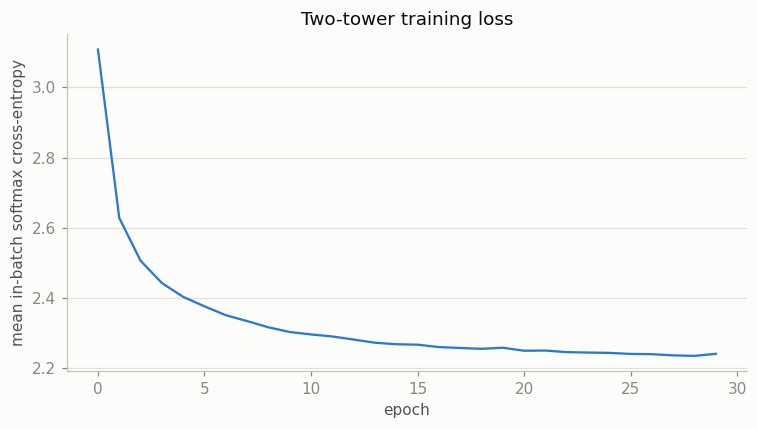

In [45]:
FINAL_EPOCHS = 30

user_tower = UserTower(mf_dim, user_numeric_feats.shape[1], embedding_dim=best_cfg["embedding_dim"]).to(DEVICE)
item_tower = ItemTower(n_items, len(categories), len(authors), item_numeric_feats.shape[1], embedding_dim=best_cfg["embedding_dim"]).to(DEVICE)
losses = train_two_tower(
    user_tower, item_tower, user_idx_arr, pos_idx_arr,
    user_history_feats_t, user_numeric_feats, item_category_idx_t, item_author_idx_t, item_numeric_feats,
    DEVICE, epochs=FINAL_EPOCHS, lr=best_cfg["lr"], temperature=TEMPERATURE, seed=SEED,
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(losses, color=CATEGORICAL[0])
ax.set_xlabel("epoch")
ax.set_ylabel("mean in-batch softmax cross-entropy")
ax.set_title("Two-tower training loss")
plt.tight_layout()
plt.show()

**Interpretation.** Unlike MF-BPR's loss (bounded below by 0, interpretable as
a probability), this loss's floor depends on batch size (`log(batch_size)` for
a uniform random model). To compare the *trend* across epochs, not the absolute
value against notebook 03's numbers.

## 8. Index with FAISS and retrieve top-100

In [46]:
user_tower.eval()
item_tower.eval()
with torch.no_grad():
    item_emb = item_tower(
        torch.arange(n_items, device=DEVICE), item_category_idx_t.to(DEVICE), item_author_idx_t.to(DEVICE), item_numeric_feats.to(DEVICE)
    ).cpu().numpy()

    val_user_idx = torch.tensor([user_to_idx[u] for u in val_users], dtype=torch.long)
    val_user_emb = user_tower(
        user_history_feats_t[val_user_idx].to(DEVICE), user_numeric_feats[val_user_idx].to(DEVICE)
    ).cpu().numpy()

    test_users = list(test_ground_truth.keys())
    test_user_idx = torch.tensor([user_to_idx[u] for u in test_users], dtype=torch.long)
    test_user_emb = user_tower(
        user_history_feats_t[test_user_idx].to(DEVICE), user_numeric_feats[test_user_idx].to(DEVICE)
    ).cpu().numpy()

index = build_faiss_index(item_emb)
val_recs = faiss_retrieve(index, val_user_emb, val_users, idx_to_item, train_history, k=100)
test_recs = faiss_retrieve(index, test_user_emb, test_users, idx_to_item, train_history, k=100)

## 9. Evaluate

In [47]:
val_metrics = evaluate(val_recs, val_ground_truth, catalog, recall_ks=(20, 50), ndcg_ks=(10,))
test_metrics = evaluate(test_recs, test_ground_truth, catalog, recall_ks=(20, 50), ndcg_ks=(10,))
print("Two-tower | val: ", val_metrics)
print("Two-tower | test:", test_metrics)

log_result(RESULTS_PATH, "retrieval", "Two-tower", "val", val_metrics)
log_result(RESULTS_PATH, "retrieval", "Two-tower", "test", test_metrics)
print("Logged to", RESULTS_PATH)

Two-tower | val:  {'recall@20': 0.04965413179887252, 'recall@50': 0.0915793516298289, 'ndcg@10': 0.015432262465108705, 'catalog_coverage': 0.9681167319030868}
Two-tower | test: {'recall@20': 0.03806153454801403, 'recall@50': 0.0763991771762182, 'ndcg@10': 0.01221755193014913, 'catalog_coverage': 0.9399494624188673}
Logged to /kaggle/working/results/metrics_sample.csv


## 10. Compare against Popularity and MF-BPR

In [48]:
import pandas as pd

dfs = []

if RESULTS_PATH.exists():
    dfs.append(pd.read_csv(RESULTS_PATH))

if BPR_RESULTS_PATH.exists():
    dfs.append(pd.read_csv(BPR_RESULTS_PATH))

if BASELINE_RESULTS_PATH.exists():
    dfs.append(pd.read_csv(BASELINE_RESULTS_PATH))

if dfs:
    all_results = pd.concat(dfs, ignore_index=True)

    comparison = (
        all_results[all_results["split"] == "test"]
        .set_index("model")
        [["recall@20", "recall@50", "ndcg@10", "catalog_coverage"]]
    )

    print(comparison)
else:
    print("No results found.")

            recall@20  recall@50   ndcg@10  catalog_coverage
model                                                       
Two-tower    0.038062   0.076399  0.012218          0.939949
MF-BPR       0.037952   0.079179  0.010997          0.310311
Random       0.000643        NaN  0.000159          0.950949
Popularity   0.007971        NaN  0.002099          0.000793


## 11. Save artifacts

In [49]:
np.save(CHECKPOINT_DIR / "item_embeddings.npy", item_emb)
torch.save({"user_tower": user_tower.state_dict(), "item_tower": item_tower.state_dict()}, CHECKPOINT_DIR / "model.pt")

with open(CHECKPOINT_DIR / "id_maps.json", "w") as f:
    json.dump({
        "user_to_idx": user_to_idx,
        "item_to_idx": item_to_idx,
        "category_to_idx": category_to_idx,
        "author_to_idx": author_to_idx,
        "best_config": best_cfg,
        "temperature": TEMPERATURE,
    }, f)

faiss.write_index(index, str(CHECKPOINT_DIR / "faiss_index.bin"))
print("Saved two-tower artifacts to", CHECKPOINT_DIR)

Saved two-tower artifacts to /kaggle/working/checkpoints/two_tower
